In [2]:
import pandas as pd

df = pd.read_csv("usf.csv")

df.columns

Index(['Timestamp', 'Are you 21 years of age or older?',
       'Have you had a completed night out within the past 30 days?',
       'Are you currently under the influence taking this survey',
       'Please enter your age', 'Which best describes your gender?',
       'What is your height?',
       'Which best describes your current education status?',
       'How financially comfortable do you currently feel?',
       'Which SF Neighborhood do you live in?',
       'Where did you receive this survey?',
       'What day of the week was this night out?',
       'How planned was this night out?',
       'At approximately what time did your night out begin?',
       'Where did you spend most of the night?', 'Did you pregame?',
       'How many people were in your group, including yourself?',
       'Who did you primarily spend the night with?',
       'What was your primary mode of transportation?',
       'Approximately how many hours did your night out last?',
       'At approximately 

In [3]:
df = df.rename(columns={"Overall, how enjoyable was this night out?" : "score"})

df.columns

Index(['Timestamp', 'Are you 21 years of age or older?',
       'Have you had a completed night out within the past 30 days?',
       'Are you currently under the influence taking this survey',
       'Please enter your age', 'Which best describes your gender?',
       'What is your height?',
       'Which best describes your current education status?',
       'How financially comfortable do you currently feel?',
       'Which SF Neighborhood do you live in?',
       'Where did you receive this survey?',
       'What day of the week was this night out?',
       'How planned was this night out?',
       'At approximately what time did your night out begin?',
       'Where did you spend most of the night?', 'Did you pregame?',
       'How many people were in your group, including yourself?',
       'Who did you primarily spend the night with?',
       'What was your primary mode of transportation?',
       'Approximately how many hours did your night out last?',
       'At approximately 

<Axes: >

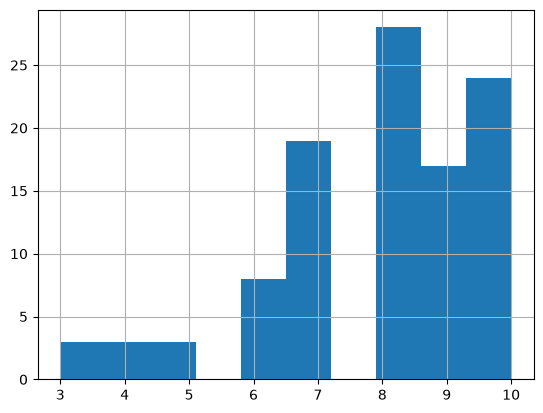

In [5]:
df['score'].hist()

In [6]:
df.to_csv("renamed.csv", index=False)

In [9]:
renamed = pd.read_csv("renamed.csv")


renamed['score']

0      NaN
1      NaN
2      3.0
3      8.0
4      8.0
      ... 
102    7.0
103    7.0
104    7.0
105    8.0
106    8.0
Name: score, Length: 107, dtype: float64

In [10]:
renamed.columns

Index(['Timestamp', 'Are you 21 years of age or older?',
       'Have you had a completed night out within the past 30 days?',
       'Are you currently under the influence taking this survey',
       'Please enter your age', 'Which best describes your gender?',
       'What is your height?',
       'Which best describes your current education status?',
       'How financially comfortable do you currently feel?',
       'Which SF Neighborhood do you live in?',
       'Where did you receive this survey?',
       'What day of the week was this night out?',
       'How planned was this night out?',
       'At approximately what time did your night out begin?',
       'Where did you spend most of the night?', 'Did you pregame?',
       'How many people were in your group, including yourself?',
       'Who did you primarily spend the night with?',
       'What was your primary mode of transportation?',
       'Approximately how many hours did your night out last?',
       'At approximately 

/var/folders/cx/qk1b249j0fs0kqqcml92l_t40000gn/T/ipykernel_92756/3603376716.py:27: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y, X).fit() # Fit OLS regression
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/regression/linear_model.py:2032: RuntimeWarning: divide by zero encountered in divide
  np.divide(self.nobs - self.k_constant, self.df_resid) * (1 - self.rsquared)
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/regression/linear_model.py:2032: RuntimeWarning: invalid value encountered in scalar multiply
  np.divide(self.nobs - self.k_constant, self.df_resid) * (1 - self.rsquared)
/opt/anaconda3/lib/python3.14/site-packages/statsmodels/regression/linear_model.py:1954: RuntimeWarning: divide by zero encountered in scalar divide
  return np.dot(wresid, wresid) / self.df_resid


NaN values:
Series([], dtype: int64)
Infinity values:
0
Data types:
const                                                                                                              float64
Please enter your age                                                                                              float64
How financially comfortable do you currently feel?                                                                 float64
Approximately how many hours did your night out last?                                                              float64
Approximately how much money did you personally spend (USD)?                                                       float64
                                                                                                                    ...   
How many locations would you like to visit?_4                                                                         bool
How many locations would you like to visit?_5+                         

TypeError: _BaseRidgeCV.__init__() got an unexpected keyword argument 'random_state'

In [15]:
# imports
import pandas as pd
import statsmodels.api as sm


from sklearn.linear_model import LassoCV, RidgeCV, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


#read in data
name = "renamed.csv" # fill in the blank
df = pd.read_csv(name)

if('Timestamp' in df.columns):
    df = df.drop(columns=['Timestamp']) # drop timestamp column if it exists




df = pd.get_dummies(df, drop_first=True, dtype=float) # convert categorical variables to dummy variables
#perform OLS
X = df.drop(columns=['score']) # Independent variables
y = df['score'] # target

X = sm.add_constant(X) # our intercept (beta_0)

model = sm.OLS(y, X).fit() # Fit OLS regression

print("OLS Regression Results:") # OLS Regression Results
print(model.summary())



#perform Lasso
X = df.drop(columns=['score']) # Independent variables
y = df['score'] # target

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2026) # train/split
scaler = StandardScaler() # scale data
X_train = scaler.fit_transform(X_train) # fit transform train data
X_test = scaler.transform(X_test) # transform test data


model = LassoCV(cv=5, random_state=2026) # create Lasso model, splits into 5 cross validation folds to find the best alpha
model.fit(X_train, y_train) # fit model
y_pred = model.predict(X_test) # predict test data

#results
print("Best alpha:", model.alpha_)
print("Lasso Regression Results:") # Lasso Regression Results
print("Mean Squared Error:", mean_squared_error(y_test, y_pred)) # Mean Squ
print("R-squared:", r2_score(y_test, y_pred)) # R-squared
print("Coefficients:", model.coef_) # Coefficients
print("Intercept:", model.intercept_) # Intercept







#perform Ridge
X = df.drop(columns=['score']) # Independent variables
y = df['score'] # target

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2026) # train/split
scaler = StandardScaler() # scale data
X_train = scaler.fit_transform(X_train) # fit transform train data
X_test = scaler.transform(X_test) # transform test data

model = RidgeCV(cv=5) # create Ridge model, splits into 5 cross validation folds to find the best alpha
model.fit(X_train, y_train) # fit model

#results


print("Ridge Regression Results:") # Ridge Regression Results
print("Best alpha:", model.alpha_)
print("Mean Squared Error:", mean_squared_error(y_test, model.predict(X_test))) # Mean Squared Error
print("R-squared:", r2_score(y_test, model.predict(X_test))) # R-squared
print("Coefficients:", model.coef_) # Coefficients




#perform Elastic Net
X = df.drop(columns=['score']) # Independent variables
y = df['score'] # target

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 2026) # train/split
scaler = StandardScaler() # scale data
X_train = scaler.fit_transform(X_train) # fit transform train data
X_test = scaler.transform(X_test) # transform test data

model = ElasticNet(alpha = 1, l1_ratio = 0.5, random_state=2026) # create Elastic Net model
model.fit(X_train, y_train) # fit model

y_pred = model.predict(X_test) # predict test data

#results
print("Elastic Net Regression Results:") # Elastic Net Regression Results
print("Mean Squared Error:", mean_squared_error(y_test, y_pred)) # Mean Squ
print("R-squared:", r2_score(y_test, y_pred)) # R-squared
print("Coefficients:", model.coef_) # Coefficients
print("Intercept:", model.intercept_) # Intercept





MissingDataError: exog contains inf or nans

In [16]:
print("Original rows:", len(df))
print("Remaining rows:", len(df.dropna()))
print("Number of predictors:", X.shape[1])

Original rows: 107
Remaining rows: 105
Number of predictors: 383


In [21]:
len(X.columns)

383